# Accessible Austin
## Computer Vision for Accessibility-Related Feature Detection

**Author:** Zainab Amir  
**Course project:** Accessible Austin  
**Project type:** Object-detection prototype for human review

This notebook develops and evaluates a YOLOv8n object detector for four visible accessibility-related features: **steps, stairs, grab bars, and ramps**. The project investigates whether computer vision can identify visible features in public-space imagery for subsequent human inspection.

> **Scope limitation:** The prototype detects visual features in images. It does not determine whether a complete route is accessible, measure every relevant design requirement, or certify ADA compliance. Its outputs are intended only to support human review.

### Project workflow
1. Retrieve the Zenodo annotation file and inspect the source dataset.
2. Visualize the original annotations and class distribution.
3. Create a reproducible 200-image pilot dataset in YOLO format.
4. Train two controlled model configurations on the same train/validation split.
5. Select a configuration using validation results only.
6. Evaluate the selected checkpoint once on the held-out test split.
7. Generate visualizations, example predictions, metrics, and a reproducibility record.

### Source dataset
The source is the [Image Dataset of Accessibility Barriers on Zenodo](https://zenodo.org/records/6382090). The source annotations contain 5,538 images and the following bounding-box totals for the four target classes: step 3,564; stair 1,492; grab bar 922; ramp 143.


## 1. Proposal changes and experimental decisions

The original proposal described using the public dataset, detecting the same four feature classes, establishing a baseline, testing augmentation/model configurations, and attempting local Austin or St. Edward's imagery when practical. The implementation retains the original problem framing and four classes, with the following documented scope changes:

- **Pilot size:** The implementation uses 200 images (160 train, 20 validation, 20 test) rather than all 5,538 images. This feasibility decision allowed the complete preprocessing-to-evaluation pipeline to be developed and tested with the available Colab resources. The smaller sample limits the generalizability of the results.
- **Local imagery:** A locally collected and annotated Austin/St. Edward's test set was not established for this project. The results therefore do not demonstrate Austin-specific performance.
- **Experiment scope:** The notebook compares two configurations while holding the dataset split, model family, image size, epochs, batch size, seed, and other settings constant. The single controlled difference is whether mosaic augmentation is enabled. This is a focused augmentation ablation, not an exhaustive hyperparameter search.
- **Evaluation:** Precision, recall, mAP@50, and mAP@50–95 are reported. IoU is used internally to match predicted boxes with ground-truth boxes when calculating detection metrics; it is not reported as a separate standalone score.

The pilot dataset is treated as a proof of concept. Training can resume from `last.pt` if an execution is interrupted. The force flags default to `False`; setting either flag to `True` triggers the corresponding dataset rebuild or model retraining operation.


## 2. Install required packages

This cell installs the packages used for data retrieval, image processing, visualization, and object detection. The workflow is designed for Google Colab, and a CUDA-enabled GPU runtime is recommended for model training. A runtime restart may be required after package installation.


In [1]:
%pip -q install ultralytics remotezip pyyaml seaborn requests pillow pandas

## 3. Imports

The imports are grouped in one cell so the rest of the notebook can use the same libraries consistently.

In [2]:
import json
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import requests
import seaborn as sns
import torch
import yaml
from PIL import Image
from remotezip import RemoteZip
from IPython.display import display, Image as IPyImage, Markdown
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 4. Project configuration

All paths and experiment settings are defined here. The force flags default to `False` so that completed work is not deleted or repeated accidentally.

In [3]:
SEED = 42
CLASS_NAMES = ["step", "stair", "grab_bar", "ramp"]
CLASS_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}

RECORD_ID = 6382090
RECORD_URL = f"https://zenodo.org/api/records/{RECORD_ID}"
ZIP_URL = (
    "https://zenodo.org/api/records/6382090/files/"
    "wm_barriers_data.zip/content"
)

WORK_DIR = Path("/content/accessible_austin_final")
XML_PATH = WORK_DIR / "wm_annotations.xml"
SAMPLE_DIR = WORK_DIR / "source_samples"
DATASET_DIR = WORK_DIR / "pilot_dataset"
RUNS_DIR = WORK_DIR / "model_runs"
ARTIFACT_DIR = WORK_DIR / "final_artifacts"

FORCE_REBUILD_DATASET = False
FORCE_RETRAIN_MODELS = False

## 5. Create working directories and set reproducibility controls

The random seed is fixed to make image selection and the experiment more repeatable. Exact training results can still vary across package versions and hardware.

In [4]:
for folder in [WORK_DIR, SAMPLE_DIR, DATASET_DIR, RUNS_DIR, ARTIFACT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = sns.color_palette("colorblind", n_colors=len(CLASS_NAMES))
DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Working directory:", WORK_DIR)
print("CUDA available:", torch.cuda.is_available())
training_device = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Training device:", training_device)

Working directory: /content/accessible_austin_final
CUDA available: True
Training device: Tesla T4


## 6. Inspect the Zenodo record

This cell confirms the dataset title and lists the remote archive. It does not download the full 7.6 GB image archive.

In [5]:
record_response = requests.get(RECORD_URL, timeout=45)
record_response.raise_for_status()
record = record_response.json()

print("Dataset title:", record["metadata"]["title"])
print("Record DOI:", record.get("doi", "Not provided in API response"))
for file_info in record.get("files", []):
    size_mb = file_info["size"] / (1024 ** 2)
    print(f"{file_info['key']}: {size_mb:,.1f} MB")

Dataset title: Image Dataset of Accessibility Barriers
Record DOI: 10.5281/zenodo.6382090
wm_barriers_data.zip: 7,603.1 MB


## 7. Retrieve the annotation XML

The annotations are read from the remote ZIP archive with `RemoteZip`. This avoids downloading the entire archive just to obtain the XML file.

In [6]:
if not XML_PATH.exists() or XML_PATH.stat().st_size == 0:
    print("Fetching annotation XML from the remote archive...")
    with RemoteZip(ZIP_URL) as remote_archive:
        xml_bytes = remote_archive.read("wm_annotations.xml")
    XML_PATH.write_bytes(xml_bytes)

print("Annotation file:", XML_PATH)
print("XML size (MB):", round(XML_PATH.stat().st_size / (1024 ** 2), 2))

Fetching annotation XML from the remote archive...
Annotation file: /content/accessible_austin_final/wm_annotations.xml
XML size (MB): 1.81


## 8. Parse the annotation XML

Each image node contains image dimensions and zero or more bounding-box annotations. The XML is parsed once and reused throughout preprocessing and visualization.

In [7]:
annotation_tree = ET.parse(XML_PATH)
annotation_root = annotation_tree.getroot()
image_nodes = annotation_root.findall(".//image")

if not image_nodes:
    raise ValueError("No image annotations were found in the XML file.")

print("Annotated image records:", len(image_nodes))
print("First image record:", image_nodes[0].get("name"))

Annotated image records: 5538
First image record: images/000143519.jpg


## 9. Summarize the full-dataset class distribution

This counts all bounding boxes in the XML, including classes outside this project's four-class scope. The target classes are then isolated for the project plots and dataset preparation.

In [8]:
all_box_counts = Counter(
    box.get("label")
    for box in annotation_root.findall(".//image/box")
)
TARGET_BOX_COUNTS = {
    class_name: all_box_counts.get(class_name, 0)
    for class_name in CLASS_NAMES
}

print("Target class bounding boxes:")
for class_name, count in TARGET_BOX_COUNTS.items():
    print(f"{class_name}: {count:,}")
print("Total target boxes:", sum(TARGET_BOX_COUNTS.values()))

Target class bounding boxes:
step: 3,564
stair: 1,492
grab_bar: 922
ramp: 143
Total target boxes: 6121


## 10. Visualize the full-dataset class distribution

This first project visualization shows how frequently each target class appears in the original annotations. The direct count labels and colorblind-friendly palette improve readability.

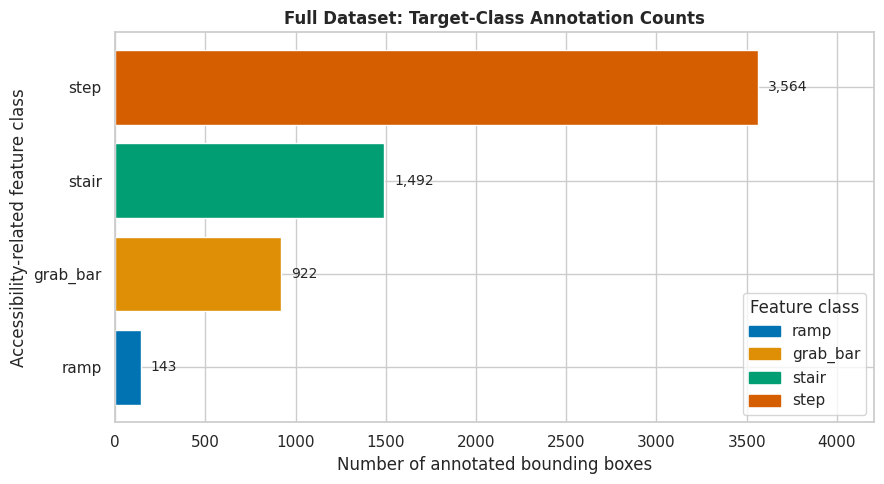

In [9]:
class_counts = pd.Series(TARGET_BOX_COUNTS).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
bar_colors = sns.color_palette("colorblind", n_colors=len(class_counts))

bars = ax.barh(class_counts.index, class_counts.values, color=bar_colors)
for bar, count in zip(bars, class_counts.values):
    ax.text(
        count + max(class_counts.values) * 0.015,
        bar.get_y() + bar.get_height() / 2,

            f"{count:,}", va="center", fontsize=10)
legend_handles = [mpatches.Patch(color=color, label=name)
                  for color, name in zip(bar_colors, class_counts.index)]
ax.set_title("Full Dataset: Target-Class Annotation Counts", weight="bold")
ax.set_xlabel("Number of annotated bounding boxes")
ax.set_ylabel("Accessibility-related feature class")
ax.legend(handles=legend_handles, title="Feature class", loc="lower right")
ax.set_xlim(0, max(class_counts.values) * 1.18)
fig.tight_layout()
fig.savefig(
    ARTIFACT_DIR / "full_dataset_class_distribution.png",
    dpi=300, bbox_inches="tight",
)
plt.show()

## 11. Build a lookup for image files in the remote archive

The archive may store images in a nested folder. This helper first tries the XML path and common image paths, then falls back to a unique filename match.

In [10]:
def find_archive_member(image_name, archive_names):
    """Return the archive member corresponding to an XML image name."""
    filename = Path(image_name).name
    candidates = [image_name, f"images/{filename}", filename]

    for candidate in candidates:
        if candidate in archive_names:
            return candidate

    matches = [name for name in archive_names if Path(name).name == filename]
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Could not uniquely locate {filename} in archive.")

## 12. Select and download source examples

Five deterministic source images are downloaded for the ground-truth annotation visualization. This is separate from the training/validation/test pilot split.

In [11]:
target_source_nodes = [
    node for node in image_nodes
    if any(box.get("label") in CLASS_TO_ID for box in node.findall("box"))
]
source_sample_nodes = random.Random(SEED).sample(
    target_source_nodes, k=min(5, len(target_source_nodes))
)
source_sample_paths = []

with RemoteZip(ZIP_URL) as remote_archive:
    archive_names = remote_archive.namelist()
    for image_node in source_sample_nodes:
        member = find_archive_member(image_node.get("name"), archive_names)
        filename = Path(image_node.get("name")).name
        output_path = SAMPLE_DIR / filename
        if not output_path.exists():
            output_path.write_bytes(remote_archive.read(member))
        source_sample_paths.append(output_path)

print("Source examples ready:", len(source_sample_paths))

Source examples ready: 5


## 13. Visualize original images with ground-truth boxes

The boxes in this figure come directly from the source XML, not from the trained model. The legend identifies the four project classes.

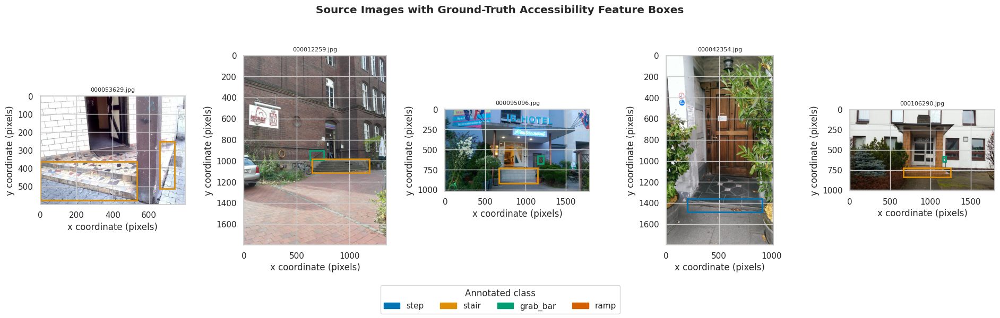

In [12]:
class_color_map = {
    class_name: PALETTE[index]
    for index, class_name in enumerate(CLASS_NAMES)
}
fig, axes = plt.subplots(1, len(source_sample_nodes), figsize=(19, 6))
if len(source_sample_nodes) == 1:
    axes = [axes]

for axis, image_node, image_path in zip(axes, source_sample_nodes, source_sample_paths):
    with Image.open(image_path) as image:
        axis.imshow(image.convert("RGB"))
    for box in image_node.findall("box"):
        label = box.get("label")
        if label not in CLASS_TO_ID:
            continue
        x1, y1 = float(box.get("xtl")), float(box.get("ytl"))
        x2, y2 = float(box.get("xbr")), float(box.get("ybr"))
        axis.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                     fill=False, linewidth=2,
                                     edgecolor=class_color_map[label]))
    axis.set_title(Path(image_path).name, fontsize=8)
    axis.set_xlabel("x coordinate (pixels)")
    axis.set_ylabel("y coordinate (pixels)")
legend_handles = [mpatches.Patch(color=color, label=name)
                  for name, color in class_color_map.items()]
fig.suptitle(
    "Source Images with Ground-Truth Accessibility Feature Boxes", weight="bold"
)
fig.legend(handles=legend_handles, title="Annotated class", loc="lower center", ncol=4)
fig.tight_layout(rect=[0, 0.12, 1, 0.93])
fig.savefig(
    ARTIFACT_DIR / "ground_truth_annotation_examples.png",
    dpi=300, bbox_inches="tight",
)
plt.show()

## 14. Define the pilot dataset layout

The split sizes match the original pilot: 160 training images, 20 validation images, and 20 held-out test images. The split is generated deterministically from the XML annotations.

In [13]:
SPLIT_SIZES = {"train": 160, "val": 20, "test": 20}
TOTAL_PILOT_IMAGES = sum(SPLIT_SIZES.values())

for split_name in SPLIT_SIZES:
    (DATASET_DIR / "images" / split_name).mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / "labels" / split_name).mkdir(parents=True, exist_ok=True)

DATA_YAML_PATH = DATASET_DIR / "data.yaml"
MANIFEST_PATH = DATASET_DIR / "split_manifest.json"
print("Pilot dataset directory:", DATASET_DIR)

Pilot dataset directory: /content/accessible_austin_final/pilot_dataset


## 15. Find eligible images and select a class-aware pilot sample

Only images containing at least one target class are eligible. A greedy selection step favors images that contain less frequently represented target classes, then the selected list is shuffled with the fixed seed before splitting.

In [14]:
eligible_image_nodes = [
    node for node in image_nodes
    if any(box.get("label") in CLASS_TO_ID for box in node.findall("box"))
]

if len(eligible_image_nodes) < TOTAL_PILOT_IMAGES:
    raise ValueError("The XML does not contain enough eligible images.")

print("Eligible images with at least one target feature:", len(eligible_image_nodes))

Eligible images with at least one target feature: 3367


## 16. Implement deterministic class-aware image selection

This function balances image-level class coverage as a practical pilot-selection heuristic. It does not guarantee perfectly equal class counts, and the resulting dataset remains much smaller than the source dataset.

In [15]:
def select_class_aware_images(candidates, target_count, seed):
    """Greedily select images that improve coverage of rarer target classes."""
    rng = random.Random(seed)
    remaining = list(candidates)
    rng.shuffle(remaining)
    selected = []
    image_coverage = Counter()

    while remaining and len(selected) < target_count:
        def coverage_score(image_node):
            labels = {box.get("label") for box in image_node.findall("box")}
            labels.intersection_update(CLASS_TO_ID)
            return sum(1 / (1 + image_coverage[label]) for label in labels)

        best_image = max(remaining, key=coverage_score)
        selected.append(best_image)
        remaining.remove(best_image)
        image_labels = {box.get("label") for box in best_image.findall("box")}
        image_coverage.update(image_labels.intersection(CLASS_TO_ID))

    if len(selected) != target_count:
        raise RuntimeError("Could not select the requested number of pilot images.")
    return selected

## 17. Create reproducible train, validation, and test splits

The split manifest records the selected filenames. Keeping the same split is important when comparing model configurations because both models must see identical images.

In [16]:
selected_image_nodes = select_class_aware_images(
    eligible_image_nodes, TOTAL_PILOT_IMAGES, SEED
)
random.Random(SEED).shuffle(selected_image_nodes)

pilot_splits = {
    "train": selected_image_nodes[:160],
    "val": selected_image_nodes[160:180],
    "test": selected_image_nodes[180:200],
}

split_manifest = {
    split_name: [Path(node.get("name")).name for node in nodes]
    for split_name, nodes in pilot_splits.items()
}
print({name: len(nodes) for name, nodes in pilot_splits.items()})

{'train': 160, 'val': 20, 'test': 20}


## 18. Check whether a previously built pilot dataset is complete

The dataset is rebuilt only when it is incomplete or when `FORCE_REBUILD_DATASET` is deliberately changed to `True`. This avoids deleting an existing valid dataset on every notebook run.

In [17]:
def dataset_is_complete(dataset_dir, split_sizes):
    """Check expected image and label counts for all pilot splits."""
    for split_name, expected_count in split_sizes.items():
        image_dir = dataset_dir / "images" / split_name
        label_dir = dataset_dir / "labels" / split_name
        image_count = len(list(image_dir.glob("*"))) if image_dir.exists() else 0
        label_count = len(list(label_dir.glob("*.txt"))) if label_dir.exists() else 0
        if image_count != expected_count or label_count != expected_count:
            return False
    if not (dataset_dir / "data.yaml").exists():
        return False
    if not MANIFEST_PATH.exists():
        return False
    try:
        saved_manifest = json.loads(MANIFEST_PATH.read_text())
    except (json.JSONDecodeError, OSError):
        return False
    return saved_manifest == split_manifest

DATASET_READY = dataset_is_complete(DATASET_DIR, SPLIT_SIZES)
print("Existing dataset complete:", DATASET_READY)

Existing dataset complete: False


## 19. Convert XML bounding boxes into YOLO label rows

YOLO object-detection labels use `class_id x_center y_center width height`, with all four box values normalized between 0 and 1. Invalid or zero-area boxes are skipped.

In [18]:
def box_to_yolo_row(box, image_width, image_height):
    """Convert one XML box to a normalized YOLO label row."""
    class_name = box.get("label")
    if class_name not in CLASS_TO_ID:
        return None

    x1 = max(0.0, float(box.get("xtl")))
    y1 = max(0.0, float(box.get("ytl")))
    x2 = min(image_width, float(box.get("xbr")))
    y2 = min(image_height, float(box.get("ybr")))
    if x2 <= x1 or y2 <= y1:
        return None

    x_center = ((x1 + x2) / 2) / image_width
    y_center = ((y1 + y2) / 2) / image_height
    box_width = (x2 - x1) / image_width
    box_height = (y2 - y1) / image_height
    values = [CLASS_TO_ID[class_name], x_center, y_center, box_width, box_height]
    return (
        f"{values[0]} {values[1]:.6f} {values[2]:.6f} "
        f"{values[3]:.6f} {values[4]:.6f}"
    )

## 20. Write the pilot images and YOLO labels

This cell fetches only selected image members from the remote archive and creates one `.txt` annotation file per image. It runs only if the pilot dataset is incomplete or the rebuild flag is enabled.

In [19]:
def build_pilot_dataset(split_nodes, dataset_dir):
    """Download missing images and write valid, newline-separated YOLO labels."""
    pending_by_split = {}

    for split_name, nodes in split_nodes.items():
        image_dir = dataset_dir / "images" / split_name
        label_dir = dataset_dir / "labels" / split_name
        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)
        pending = []

        for node in nodes:
            filename = Path(node.get("name")).name
            image_path = image_dir / filename
            label_path = label_dir / f"{Path(filename).stem}.txt"
            image_ready = image_path.exists() and image_path.stat().st_size > 0
            if not (image_ready and label_path.exists()):
                pending.append((node, image_path, label_path))
        pending_by_split[split_name] = pending

    total_pending = sum(len(items) for items in pending_by_split.values())
    if total_pending == 0:
        print("All selected images and labels already exist; reusing them.")
        return

    print(f"Files still needing preparation: {total_pending}")
    with RemoteZip(ZIP_URL) as remote_archive:
        archive_names = remote_archive.namelist()
        for split_name, pending in pending_by_split.items():
            print(f"Building {split_name}: {len(pending)} images remaining")
            for position, (node, image_path, label_path) in enumerate(
                pending, start=1
            ):
                member = find_archive_member(node.get("name"), archive_names)
                image_bytes = remote_archive.read(member)
                if not image_bytes:
                    raise RuntimeError(f"Downloaded an empty image: {member}")
                image_path.write_bytes(image_bytes)

                width, height = float(node.get("width")), float(node.get("height"))
                rows = [box_to_yolo_row(box, width, height)
                        for box in node.findall("box")]
                rows = [row for row in rows if row is not None]
                label_text = "\n".join(rows) + ("\n" if rows else "")
                label_path.write_text(label_text, encoding="utf-8")
                if position % 20 == 0 or position == len(pending):
                    print(f"  {split_name}: {position}/{len(pending)}")


## 21. Build or resume the pilot dataset

The dataset builder skips image/label pairs that are already complete, allowing an interrupted download or preprocessing run to continue without repeating completed work. The dataset is rebuilt only when it is incomplete or when `FORCE_REBUILD_DATASET` is set to `True`.

The following label normalization and validation cells run before the dataset is passed to YOLO. They do not require another image download.


In [20]:
if FORCE_REBUILD_DATASET or not DATASET_READY:
    if FORCE_REBUILD_DATASET and DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)
    print("Preparing or resuming pilot dataset...")
    build_pilot_dataset(pilot_splits, DATASET_DIR)
else:
    print("Reusing the existing complete pilot dataset.")

config = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": CLASS_NAMES,
}
DATA_YAML_PATH.write_text(yaml.safe_dump(config, sort_keys=False))
MANIFEST_PATH.write_text(json.dumps(split_manifest, indent=2))
print("Dataset YAML:", DATA_YAML_PATH)

Preparing or resuming pilot dataset...
Files still needing preparation: 200
Building train: 160 images remaining
  train: 20/160
  train: 40/160
  train: 60/160
  train: 80/160
  train: 100/160
  train: 120/160
  train: 140/160
  train: 160/160
Building val: 20 images remaining
  val: 20/20
Building test: 20 images remaining
  test: 20/20
Dataset YAML: /content/accessible_austin_final/pilot_dataset/data.yaml


### Label-file repair and validation

This separate check normalizes any literal escaped newline sequences left by an earlier run, removes stale Ultralytics cache files, and verifies the five-column YOLO label format. It runs before training so malformed labels cannot silently invalidate the dataset.

In [21]:
# Normalize and validate all YOLO label files before training.
from math import isfinite

label_files = sorted((DATASET_DIR / "labels").rglob("*.txt"))
if len(label_files) != sum(SPLIT_SIZES.values()):
    raise RuntimeError("Expected one YOLO label file per pilot image.")

repaired_files, invalid_rows = 0, []
for label_path in label_files:
    raw_text = label_path.read_text(encoding="utf-8")
    fixed_text = raw_text.replace("\\r\\n", "\n")
    fixed_text = fixed_text.replace("\\n", "\n").replace("\\r", "\n")
    fixed_text = fixed_text.replace("\r\n", "\n").replace("\r", "\n")
    if fixed_text != raw_text:
        label_path.write_text(fixed_text, encoding="utf-8")
        repaired_files += 1

    for row_number, line in enumerate(fixed_text.splitlines(), 1):
        fields = line.split()
        if not fields:
            continue
        try:
            class_id = float(fields[0])
            coords = [float(value) for value in fields[1:]]
            valid = (
                len(fields) == 5 and class_id.is_integer()
                and 0 <= int(class_id) < len(CLASS_NAMES)
                and len(coords) == 4
                and all(isfinite(v) and 0 <= v <= 1 for v in coords)
                and coords[2] > 0 and coords[3] > 0
            )
            if not valid:
                raise ValueError("Invalid YOLO row")
        except (ValueError, OverflowError):
            invalid_rows.append((label_path.name, row_number, line))

for cache_path in DATASET_DIR.rglob("*.cache"):
    cache_path.unlink(missing_ok=True)

print("Label files:", len(label_files), "| Repaired:", repaired_files)
print("Invalid rows:", len(invalid_rows))
if invalid_rows:
    print("Examples:", invalid_rows[:5])
    raise ValueError("YOLO labels remain invalid; stop before training.")
print("All YOLO label files are valid.")

Label files: 200 | Repaired: 0
Invalid rows: 0
All YOLO label files are valid.


## 22. Validate the prepared dataset

The image and label counts are checked before training. This catches missing files early rather than allowing a training run to fail much later.

In [22]:
for split_name, expected_count in SPLIT_SIZES.items():
    image_files = list((DATASET_DIR / "images" / split_name).glob("*"))
    label_files = list((DATASET_DIR / "labels" / split_name).glob("*.txt"))
    print(f"{split_name:>5}: {len(image_files)} images, {len(label_files)} label files")
    if len(image_files) != expected_count or len(label_files) != expected_count:
        raise RuntimeError(f"Unexpected file count in {split_name} split.")

print("Dataset structure validation passed.")

train: 160 images, 160 label files
  val: 20 images, 20 label files
 test: 20 images, 20 label files
Dataset structure validation passed.


## 23. Count instances in each split

The YOLO label files use integer class IDs. This cell counts the number of bounding-box instances for each target class in train, validation, and test.

In [23]:
def count_yolo_instances(label_directory):
    """Count class IDs from all YOLO label files in one split."""
    counts = Counter()
    for label_file in Path(label_directory).glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[CLASS_NAMES[class_id]] += 1
    return counts

split_instance_counts = {
    split_name: count_yolo_instances(DATASET_DIR / "labels" / split_name)
    for split_name in SPLIT_SIZES
}
print(pd.DataFrame(split_instance_counts).fillna(0).astype(int))

          train  val  test
stair       170   18    20
grab_bar    233   24    32
step        206   26    21
ramp         71    9    12


## 24. Visualize class balance across the three splits

This grouped bar chart checks how many annotated instances of each class are available to training, validation, and testing. It makes class imbalance and the small validation/test samples visible.

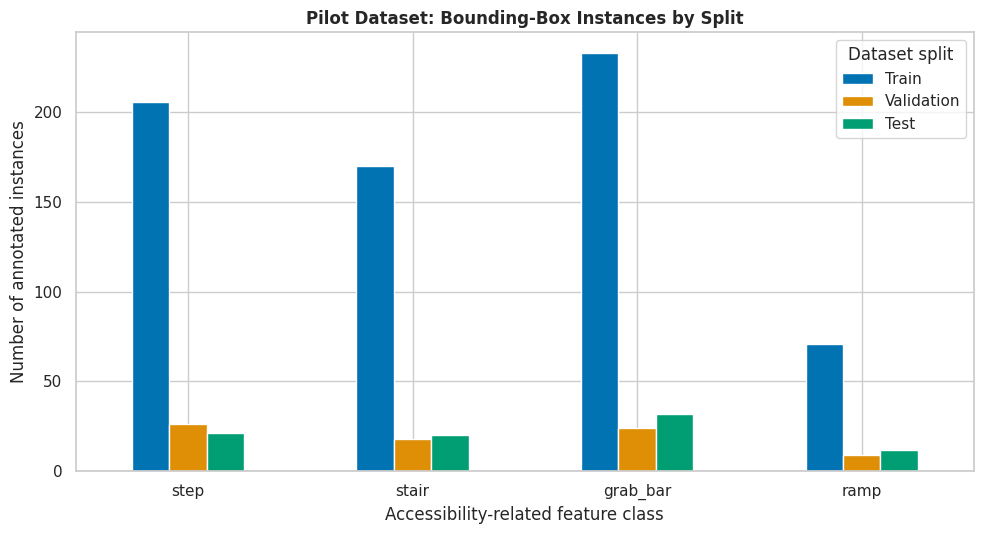

In [24]:
split_plot_data = pd.DataFrame(split_instance_counts).reindex(CLASS_NAMES).fillna(0)
split_plot_data.columns = ["Train", "Validation", "Test"]
fig, ax = plt.subplots(figsize=(10, 5.5))
split_plot_data.plot(kind="bar", ax=ax, color=sns.color_palette("colorblind", 3))
ax.set_title("Pilot Dataset: Bounding-Box Instances by Split", weight="bold")
ax.set_xlabel("Accessibility-related feature class")
ax.set_ylabel("Number of annotated instances")
ax.legend(title="Dataset split")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(
    ARTIFACT_DIR / "pilot_split_class_distribution.png",
    dpi=300, bbox_inches="tight",
)
plt.show()

## 25. Define the shared training configuration

Both models use the same pretrained YOLOv8n architecture and training settings. The experiment changes only the mosaic augmentation setting.

In [25]:
TRAINING_SETTINGS = {
    "epochs": 30,
    "imgsz": 640,
    "batch": 8,
    "patience": 8,
    "seed": SEED,
    "deterministic": True,
    "workers": 2,
    "device": DEVICE,
    "plots": True,
}

EXPERIMENTS = {
    "default_mosaic": {"mosaic": 1.0, "close_mosaic": 10},
    "no_mosaic": {"mosaic": 0.0, "close_mosaic": 0},
}
print("Training settings:", TRAINING_SETTINGS)
print("Experiment variants:", EXPERIMENTS)

Training settings: {'epochs': 30, 'imgsz': 640, 'batch': 8, 'patience': 8, 'seed': 42, 'deterministic': True, 'workers': 2, 'device': 0, 'plots': True}
Experiment variants: {'default_mosaic': {'mosaic': 1.0, 'close_mosaic': 10}, 'no_mosaic': {'mosaic': 0.0, 'close_mosaic': 0}}


## 26. Define a safe training/resume function

A completed `best.pt` checkpoint is reused by default. If only `last.pt` exists, the function resumes the interrupted run. A CUDA GPU is required for new or resumed training; the function stops with instructions rather than silently running the experiments on CPU. The `FORCE_RETRAIN_MODELS` flag can be set to `True` to deliberately delete and retrain an experiment directory.


In [26]:
def train_experiment(experiment_name, augmentation_settings):
    """Train, resume, or reuse one YOLOv8n experiment safely."""
    experiment_dir = RUNS_DIR / experiment_name
    weights_dir = experiment_dir / "weights"
    best_checkpoint = weights_dir / "best.pt"
    last_checkpoint = weights_dir / "last.pt"
    completion_marker = experiment_dir / "TRAINING_COMPLETE.txt"

    if FORCE_RETRAIN_MODELS and experiment_dir.exists():
        shutil.rmtree(experiment_dir)

    if completion_marker.exists() and best_checkpoint.exists():
        print(f"Using completed checkpoint: {best_checkpoint}")
        return best_checkpoint

    if not torch.cuda.is_available():
        raise RuntimeError(
            "A CUDA GPU is required. In Colab, select Runtime > "
            "Change runtime type > T4 GPU."
        )

    if last_checkpoint.exists():
        print(f"Resuming interrupted experiment: {experiment_name}")
        model = YOLO(str(last_checkpoint))
        model.train(resume=True)
    else:
        model = YOLO("yolov8n.pt")
        model.train(
            data=str(DATA_YAML_PATH),
            project=str(RUNS_DIR),
            name=experiment_name,
            exist_ok=True,
            **TRAINING_SETTINGS,
            **augmentation_settings,
        )

    if not best_checkpoint.exists():
        raise FileNotFoundError(f"Training did not create {best_checkpoint}")

    completion_marker.write_text(
        "Training completed successfully.\n", encoding="utf-8"
    )
    return best_checkpoint

## 27. Train the default-mosaic configuration

This is the baseline configuration. Mosaic augmentation is enabled at the standard YOLO setting; other shared settings are defined above.

In [27]:
# Train or reuse the default-mosaic baseline.
DEFAULT_CHECKPOINT = train_experiment(
    "default_mosaic", EXPERIMENTS["default_mosaic"]
)
print("Default-mosaic checkpoint:", DEFAULT_CHECKPOINT)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/accessible_austin_final/pilot_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=default_mosaic, nbs=64, nms=None,

## 28. Train the no-mosaic comparison configuration

This run uses the same data split and training settings but sets `mosaic=0`. Other YOLO augmentation defaults remain in place, so this experiment isolates the contribution of mosaic rather than turning off every augmentation.

In [28]:
# Train or reuse the no-mosaic comparison model.
NO_MOSAIC_CHECKPOINT = train_experiment(
    "no_mosaic", EXPERIMENTS["no_mosaic"]
)
print("No-mosaic checkpoint:", NO_MOSAIC_CHECKPOINT)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/accessible_austin_final/pilot_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=no_mosaic, nbs=64, nms=None, opset

## 29. Define validation-only model scoring

Validation scores are used to compare configurations and select the final checkpoint. The held-out test split is not used for model selection.

In [29]:
def evaluate_validation_checkpoint(experiment_name, checkpoint_path):
    """Evaluate one checkpoint on the validation split only."""
    validation_model = YOLO(str(checkpoint_path))
    validation_result = validation_model.val(
        data=str(DATA_YAML_PATH), split="val", imgsz=640, batch=8,
        plots=False, project=str(RUNS_DIR),
        name=f"{experiment_name}_validation", exist_ok=True,
    )
    return {
        "experiment": experiment_name,
        "precision": float(validation_result.box.mp),
        "recall": float(validation_result.box.mr),
        "map50": float(validation_result.box.map50),
        "map50_95": float(validation_result.box.map),
        "checkpoint": str(checkpoint_path),
    }

## 30. Compare both configurations on validation data

The model with the higher validation mAP@50–95 is selected. This is a stricter localization metric because it averages performance across IoU thresholds from 0.50 to 0.95.

In [30]:
# Compare both checkpoints using validation data only.
validation_scores = [
    evaluate_validation_checkpoint("default_mosaic", DEFAULT_CHECKPOINT),
    evaluate_validation_checkpoint("no_mosaic", NO_MOSAIC_CHECKPOINT),
]
validation_table = pd.DataFrame(validation_scores)
display(validation_table[["experiment", "precision", "recall", "map50", "map50_95"]])

best_validation_score = max(
    validation_scores, key=lambda row: row["map50_95"]
)
SELECTED_EXPERIMENT = best_validation_score["experiment"]
SELECTED_CHECKPOINT = Path(best_validation_score["checkpoint"])
print("Selected using validation mAP@50–95:", SELECTED_EXPERIMENT)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4748.9±490.6 MB/s, size: 1393.0 KB)
val: Scanning /content/accessible_austin_final/pilot_dataset/labels/val.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 6.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.5it/s 0.9s
                   all         20         77      0.667      0.317      0.376      0.229
                  step         17         26      0.336      0.115      0.199     0.0861
                 stair         15         18        0.7      0.556      0.549      0.388
              grab_bar         16         24      0.776      0.375      0.455      0.281
                  ramp          8          9      0.858      0.222      0.301      0.163
Speed: 1.4ms preprocess,

,experiment,precision,recall,map50,map50_95
0,default_mosaic,0.667499,0.317041,0.375858,0.229455
1,no_mosaic,0.515348,0.408647,0.403189,0.218969


Selected using validation mAP@50–95: default_mosaic


## 31. Visualize validation learning curves

The curves below compare validation mAP@50 and mAP@50–95 across training epochs. They help show whether the models improved during training and whether the two augmentation configurations behaved differently.

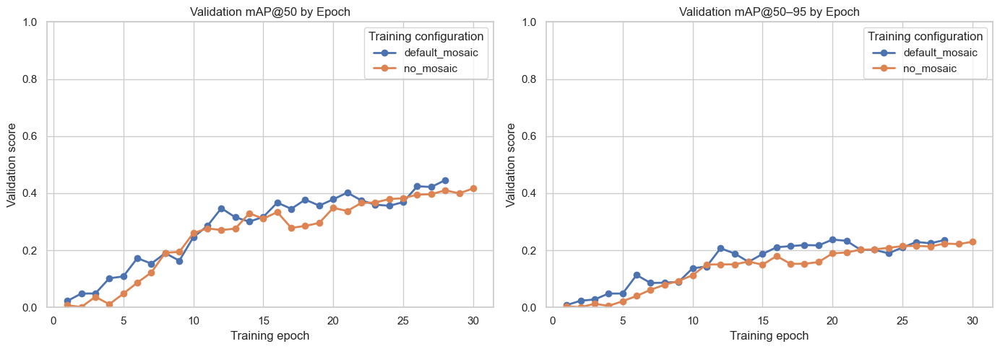

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
metric_columns = ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]
metric_titles = ["Validation mAP@50 by Epoch", "Validation mAP@50–95 by Epoch"]

for axis, metric_column, title in zip(axes, metric_columns, metric_titles):
    for experiment_name in EXPERIMENTS:
        results_path = RUNS_DIR / experiment_name / "results.csv"
        if not results_path.exists():
            raise FileNotFoundError(f"Training history not found: {results_path}")
        history = pd.read_csv(results_path)
        history.columns = history.columns.str.strip()
        axis.plot(history["epoch"], history[metric_column],
                  marker="o", linewidth=2, label=experiment_name)
    axis.set_title(title, weight="bold")
    axis.set_xlabel("Training epoch")
    axis.set_ylabel("Validation score")
    axis.set_ylim(0, 1)
    axis.legend(title="Training configuration")
fig.tight_layout()
fig.savefig(
    ARTIFACT_DIR / "validation_learning_curves.png",
    dpi=300, bbox_inches="tight",
)
plt.show()

## 32. Load the selected checkpoint

The model selected using validation data is loaded for final evaluation and prediction examples.

In [32]:
if not SELECTED_CHECKPOINT.exists():
    raise FileNotFoundError(f"Selected checkpoint missing: {SELECTED_CHECKPOINT}")

final_model = YOLO(str(SELECTED_CHECKPOINT))
print("Final model configuration:", SELECTED_EXPERIMENT)
print("Checkpoint:", SELECTED_CHECKPOINT)

Final model configuration: default_mosaic
Checkpoint: /content/accessible_austin_final/model_runs/default_mosaic/weights/best.pt


## 33. Generate fresh validation predictions

The prediction folder is recreated for the selected checkpoint so that old images from an earlier model cannot be mistaken for current outputs. The confidence threshold is set to 0.15 for visual inspection; it is not the threshold used to select the model.

In [33]:
VALIDATION_PRED_DIR = RUNS_DIR / "selected_validation_predictions"
if VALIDATION_PRED_DIR.exists():
    shutil.rmtree(VALIDATION_PRED_DIR)

final_model.predict(
    source=str(DATASET_DIR / "images" / "val"),
    conf=0.15, save=True, project=str(RUNS_DIR),
    name="selected_validation_predictions", exist_ok=True,
)
print("Fresh validation predictions saved to:", VALIDATION_PRED_DIR)


image 1/20 /content/accessible_austin_final/pilot_dataset/images/val/000014707.jpg: 480x640 1 step, 8.0ms
image 2/20 /content/accessible_austin_final/pilot_dataset/images/val/000015115.jpg: 448x640 1 step, 1 stair, 1 grab_bar, 23.2ms
image 3/20 /content/accessible_austin_final/pilot_dataset/images/val/000019976.jpg: 640x480 1 stair, 2 grab_bars, 26.3ms
image 4/20 /content/accessible_austin_final/pilot_dataset/images/val/000035789.jpg: 640x480 2 steps, 1 grab_bar, 8.6ms
image 5/20 /content/accessible_austin_final/pilot_dataset/images/val/000040043.jpg: 640x480 4 steps, 1 stair, 1 grab_bar, 9.8ms
image 6/20 /content/accessible_austin_final/pilot_dataset/images/val/000041770.jpg: 480x640 1 step, 3 grab_bars, 9.3ms
image 7/20 /content/accessible_austin_final/pilot_dataset/images/val/000042866.jpg: 640x448 1 stair, 23.3ms
image 8/20 /content/accessible_austin_final/pilot_dataset/images/val/000059169.jpg: 384x640 1 step, 1 ramp, 24.7ms
image 9/20 /content/accessible_austin_final/pilot_datas

## 34. Display validation prediction examples

The validation predictions provide qualitative examples of missed objects, false positives, and bounding-box placement. These examples complement the numerical evaluation and are interpreted cautiously because the validation split contains only 20 images.


000035789.jpg


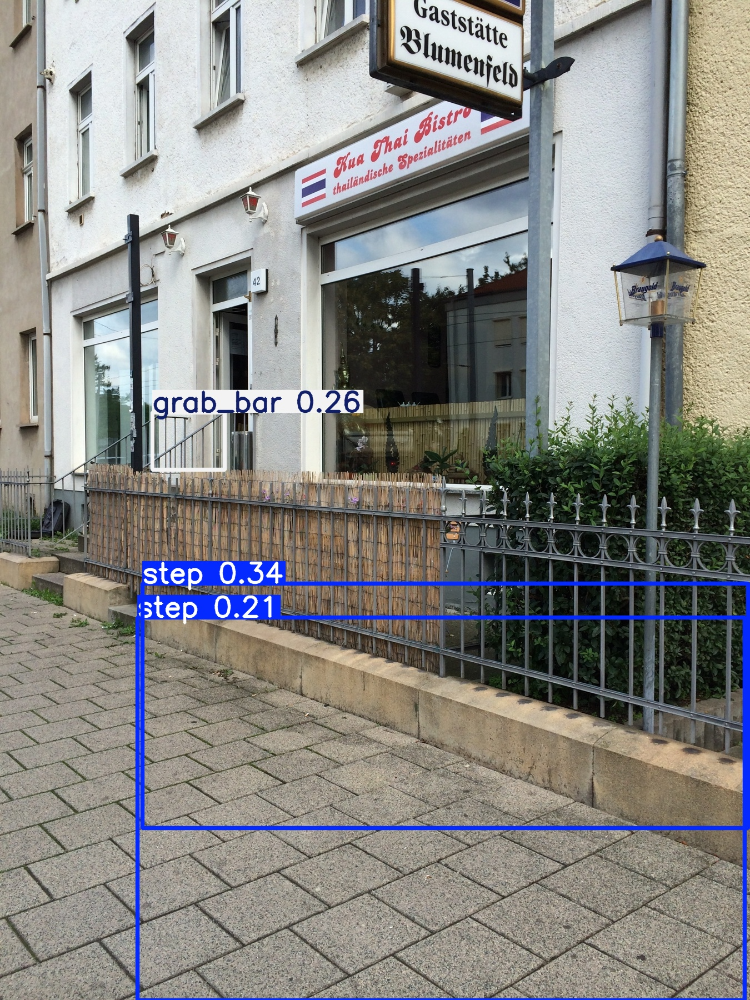

000014707.jpg


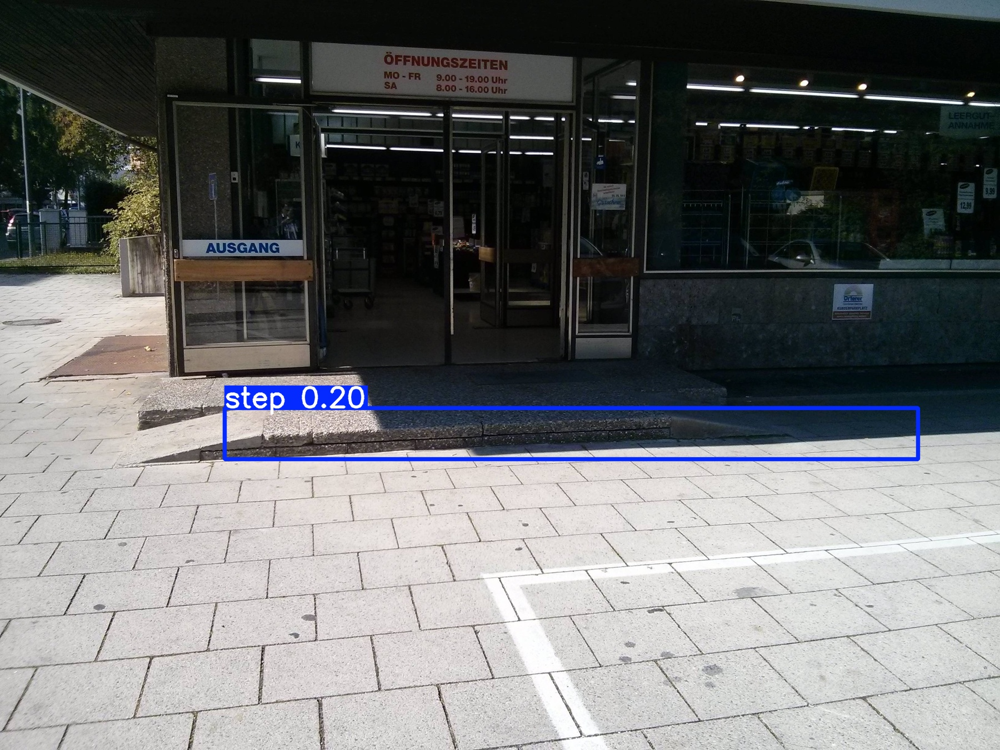

000081206.jpg


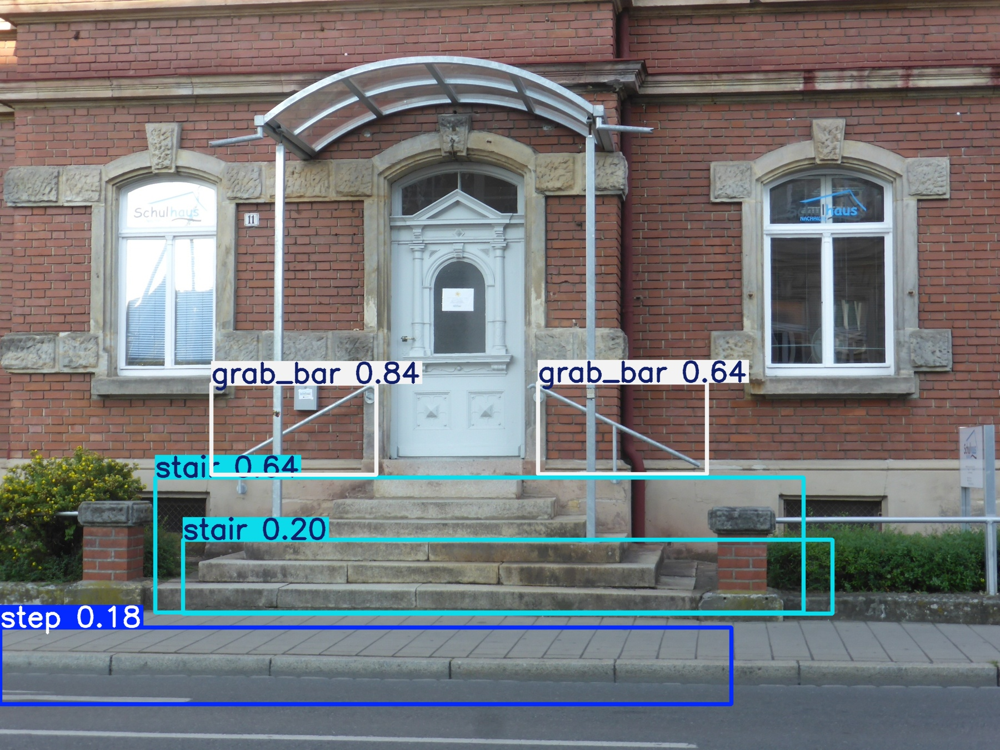

000059169.jpg


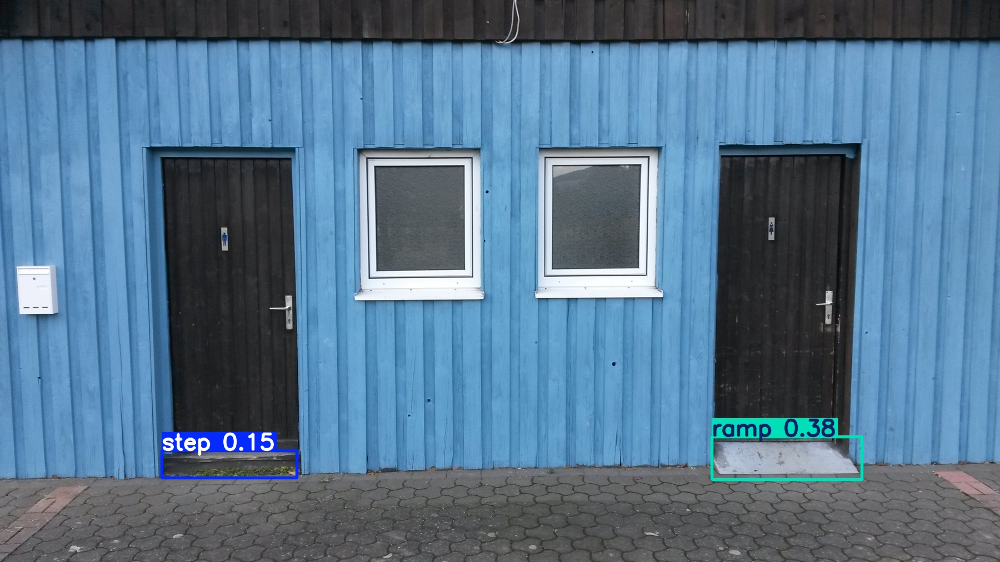

000104518.jpg


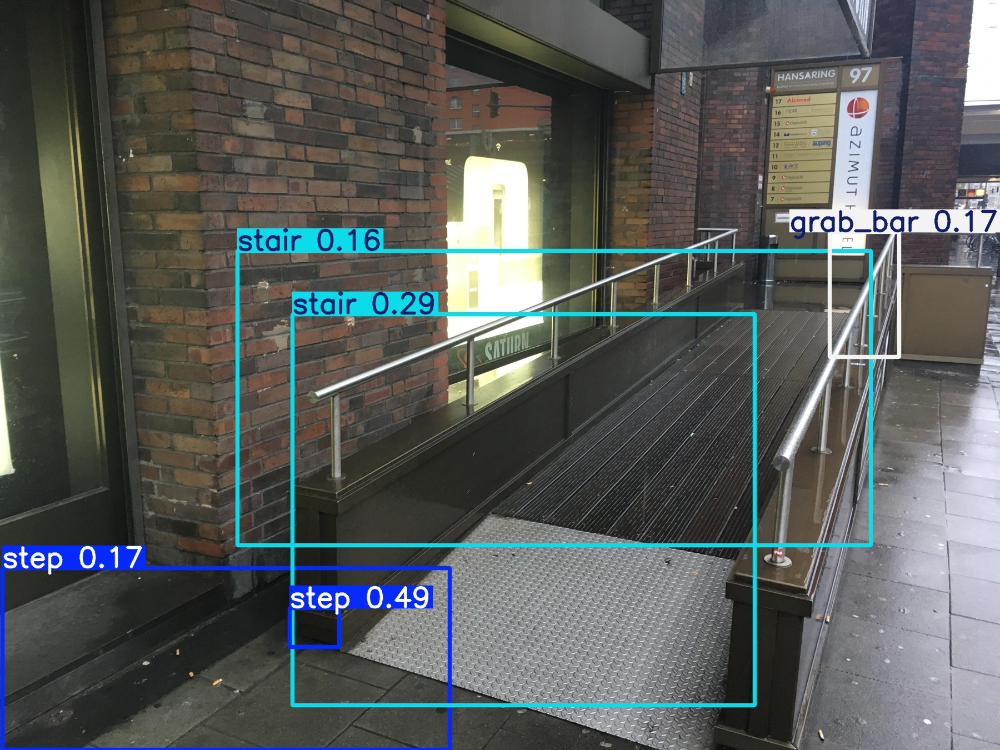

000019976.jpg


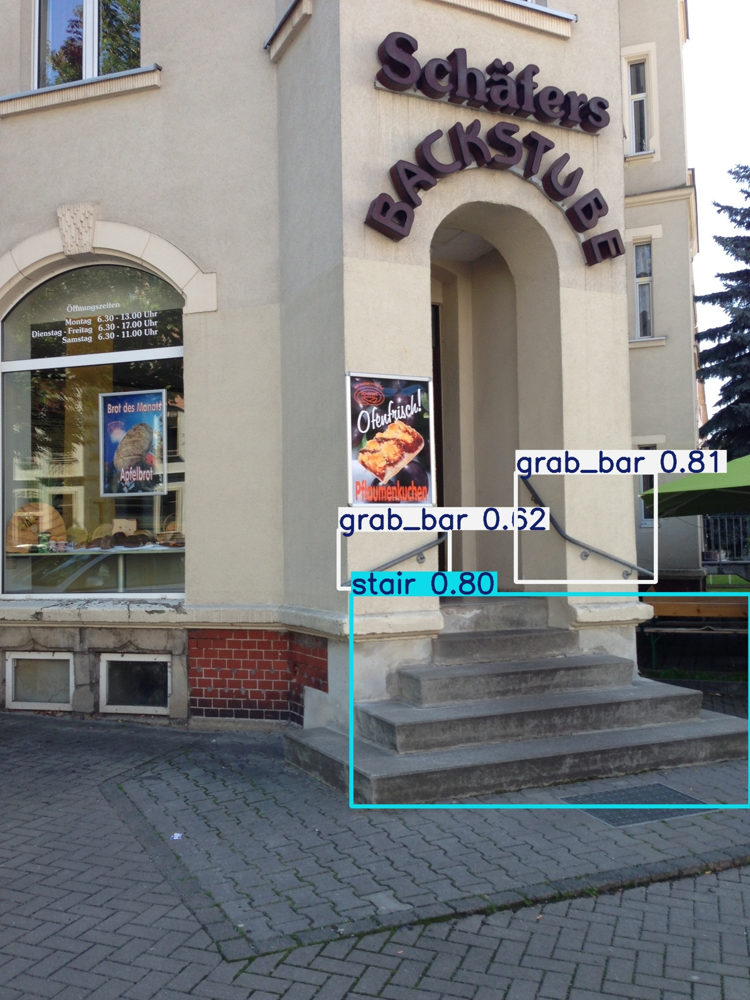

In [34]:
validation_prediction_files = sorted(VALIDATION_PRED_DIR.glob("*.jpg"))
if not validation_prediction_files:
    raise FileNotFoundError("No validation prediction images were generated.")

preview_rng = random.Random(SEED)
preview_files = preview_rng.sample(
    validation_prediction_files, k=min(6, len(validation_prediction_files))
)
for prediction_file in preview_files:
    print(prediction_file.name)
    display(IPyImage(filename=str(prediction_file), width=520))

## 35. Evaluate the selected model on the held-out test split

This is the final quantitative evaluation, performed only after configuration selection is complete. The held-out test split is not used for model or threshold selection. Further model development would require a new test set or a separate project iteration.


In [35]:
TEST_EVAL_DIR = RUNS_DIR / "selected_test_evaluation"
if TEST_EVAL_DIR.exists():
    shutil.rmtree(TEST_EVAL_DIR)

final_test_results = final_model.val(
    data=str(DATA_YAML_PATH), split="test", imgsz=640, batch=8,
    plots=True, project=str(RUNS_DIR),
    name="selected_test_evaluation", exist_ok=True,
)

print("Test split evaluated with:", SELECTED_EXPERIMENT)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2876.3±1305.9 MB/s, size: 1659.0 KB)
val: Scanning /content/accessible_austin_final/pilot_dataset/labels/test... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 835.6it/s 0.0s
val: New cache created: /content/accessible_austin_final/pilot_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.4it/s 2.1s
                   all         20         85       0.72       0.27       0.37      0.209
                  step         15         21      0.537      0.143      0.196     0.0916
                 stair         19         20       0.85       0.55      0.641      0.418
              grab_bar         18         32      0.793      0.219      0.436      0.258
                  ramp     

## 36. Record the overall test metrics

Precision measures the share of predicted detections that are correct; recall measures the share of annotated objects found. mAP@50 evaluates average precision at IoU 0.50, while mAP@50–95 averages over stricter IoU thresholds.

In [36]:
FINAL_TEST_METRICS = {
    "precision": float(final_test_results.box.mp),
    "recall": float(final_test_results.box.mr),
    "map50": float(final_test_results.box.map50),
    "map50_95": float(final_test_results.box.map),
    "test_images": SPLIT_SIZES["test"],
    "test_instances": int(
        sum(count_yolo_instances(DATASET_DIR / "labels" / "test").values())
    ),
    "selected_experiment": SELECTED_EXPERIMENT,
}

for metric_name, metric_value in FINAL_TEST_METRICS.items():
    print(f"{metric_name}: {metric_value}")

precision: 0.7200995147278593
recall: 0.2695684523809524
map50: 0.37026147220823724
map50_95: 0.20894558747868036
test_images: 20
test_instances: 85
selected_experiment: default_mosaic


## 37. Visualize the final overall test metrics

All four scores share the same 0–1 scale, so they can be shown together. The chart uses direct value labels, clear axis labels, and a legend.

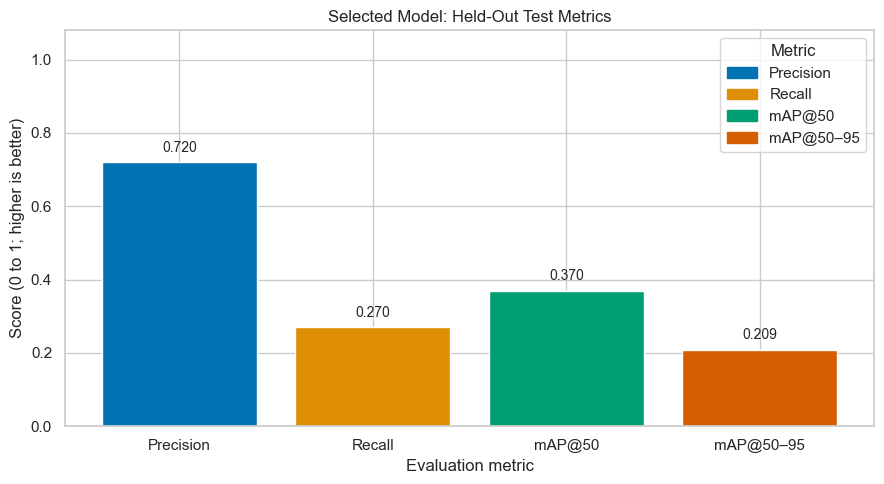

In [37]:
metric_labels = ["Precision", "Recall", "mAP@50", "mAP@50–95"]
metric_values = [
    FINAL_TEST_METRICS["precision"], FINAL_TEST_METRICS["recall"],
    FINAL_TEST_METRICS["map50"], FINAL_TEST_METRICS["map50_95"],
]
metric_colors = sns.color_palette("colorblind", n_colors=len(metric_labels))
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(metric_labels, metric_values, color=metric_colors)
for bar, value in zip(bars, metric_values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02,
            f"{value:.3f}", ha="center", va="bottom", fontsize=10)
legend_handles = [mpatches.Patch(color=color, label=label)
                  for color, label in zip(metric_colors, metric_labels)]
ax.set_title("Selected Model: Held-Out Test Metrics", weight="bold")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score (0 to 1; higher is better)")
ax.set_ylim(0, 1.08)
ax.legend(handles=legend_handles, title="Metric", loc="upper right")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "held_out_test_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

## 38. Extract per-class test metrics

Per-class results help identify which feature types are easier or harder for the model. Classes with no test annotations would be represented as zero; the pilot split should contain examples of all four classes.

In [38]:
class_indices_present = list(final_test_results.box.ap_class_index)
per_class_rows = []

for class_index, class_name in enumerate(CLASS_NAMES):
    if class_index in class_indices_present:
        metric_position = class_indices_present.index(class_index)
        class_precision, class_recall, class_map50, class_map = (
            final_test_results.box.class_result(metric_position)
        )
    else:
        class_precision, class_recall, class_map50, class_map = 0, 0, 0, 0
    per_class_rows.append({
        "class": class_name,
        "precision": float(class_precision),
        "recall": float(class_recall),
        "map50": float(class_map50),
        "map50_95": float(class_map),
    })

per_class_metrics = pd.DataFrame(per_class_rows)
display(per_class_metrics)

,class,precision,recall,map50,map50_95
0,step,0.536568,0.142857,0.196401,0.091617
1,stair,0.850264,0.550000,0.641296,0.417920
2,grab_bar,0.792923,0.218750,0.435692,0.257598
3,ramp,0.700644,0.166667,0.207657,0.068647


## 39. Visualize per-class average precision

This plot makes class-level variation visible. A lower score for one class may reflect fewer training examples, visual ambiguity, annotation differences, or other dataset limitations; it should not be attributed to one cause without further analysis.

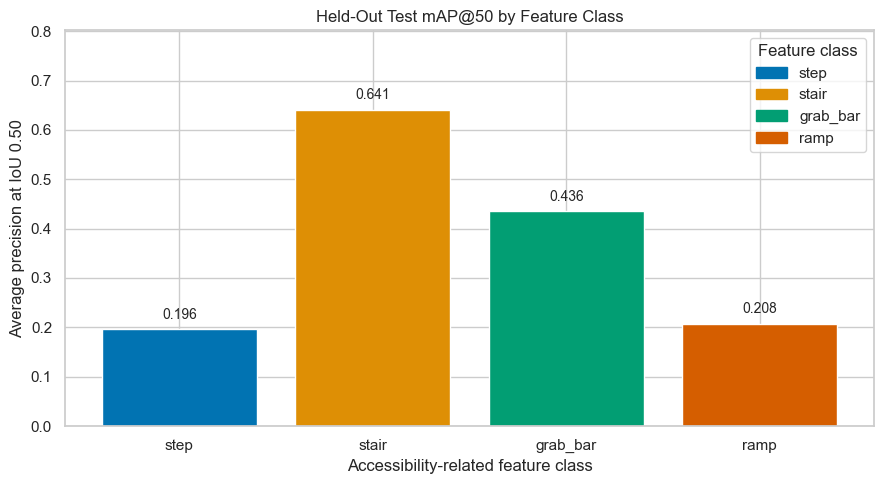

In [39]:
class_ap = per_class_metrics.set_index("class")["map50"].reindex(CLASS_NAMES)
fig, ax = plt.subplots(figsize=(9, 5))
class_colors = sns.color_palette("colorblind", n_colors=len(CLASS_NAMES))
bars = ax.bar(class_ap.index, class_ap.values, color=class_colors)
for bar, value in zip(bars, class_ap.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015,
            f"{value:.3f}", ha="center", va="bottom", fontsize=10)
legend_handles = [mpatches.Patch(color=color, label=name)
                  for color, name in zip(class_colors, CLASS_NAMES)]
ax.set_title("Held-Out Test mAP@50 by Feature Class", weight="bold")
ax.set_xlabel("Accessibility-related feature class")
ax.set_ylabel("Average precision at IoU 0.50")
ax.set_ylim(0, max(0.1, float(class_ap.max()) * 1.25))
ax.legend(handles=legend_handles, title="Feature class", loc="upper right")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "per_class_test_map50.png", dpi=300, bbox_inches="tight")
plt.show()

## 40. Inspect representative held-out test predictions

The test examples are displayed after the final metric calculation. They are for qualitative reporting only and must not be used to tune the selected model.

In [40]:
TEST_PRED_DIR = RUNS_DIR / "test_prediction_examples"
if TEST_PRED_DIR.exists():
    shutil.rmtree(TEST_PRED_DIR)

final_model.predict(
    source=str(DATASET_DIR / "images" / "test"),
    conf=0.15, save=True, project=str(RUNS_DIR),
    name="test_prediction_examples", exist_ok=True,
)
test_prediction_files = sorted(TEST_PRED_DIR.glob("*.jpg"))
print("Test prediction examples available:", len(test_prediction_files))


image 1/20 /content/accessible_austin_final/pilot_dataset/images/test/000001604.jpg: 640x480 1 step, 2 stairs, 1 grab_bar, 10.1ms
image 2/20 /content/accessible_austin_final/pilot_dataset/images/test/000029831.jpg: 480x640 5 steps, 9.6ms
image 3/20 /content/accessible_austin_final/pilot_dataset/images/test/000033974.jpg: 640x480 1 stair, 11.1ms
image 4/20 /content/accessible_austin_final/pilot_dataset/images/test/000034529.jpg: 640x480 3 steps, 1 stair, 3 grab_bars, 1 ramp, 8.6ms
image 5/20 /content/accessible_austin_final/pilot_dataset/images/test/000043931.jpg: 480x640 1 step, 1 stair, 1 ramp, 9.1ms
image 6/20 /content/accessible_austin_final/pilot_dataset/images/test/000048030.jpg: 640x480 1 stair, 1 grab_bar, 10.2ms
image 7/20 /content/accessible_austin_final/pilot_dataset/images/test/000052959.jpg: 480x640 1 step, 2 stairs, 1 ramp, 11.4ms
image 8/20 /content/accessible_austin_final/pilot_dataset/images/test/000080587.jpg: 640x384 2 stairs, 1 grab_bar, 10.0ms
image 9/20 /content/a

## 41. Display selected test prediction examples

The displayed test predictions provide qualitative examples of successful detections, missed objects, false positives, and bounding-box placement. They are illustrative only; the small test set limits broad conclusions.


000029831.jpg


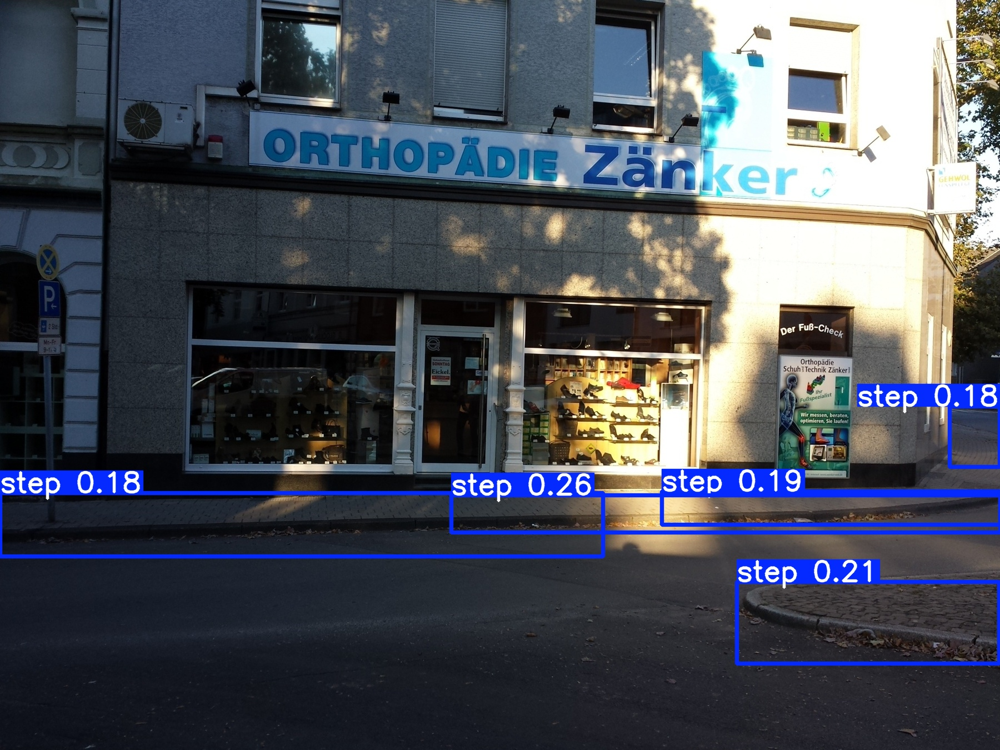

000085105.jpg


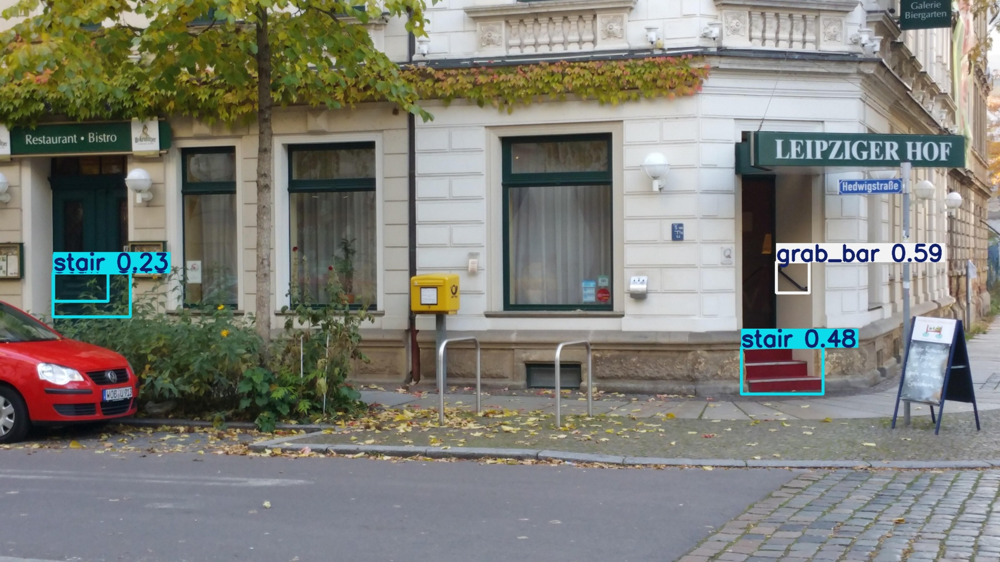

000043931.jpg


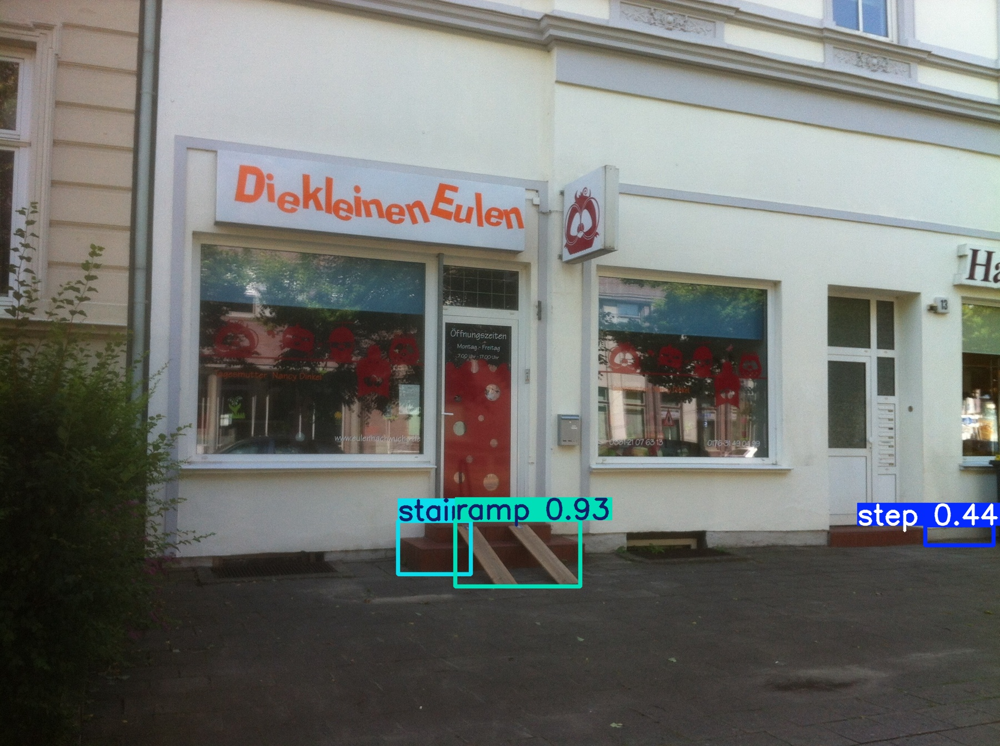

000124860.jpg


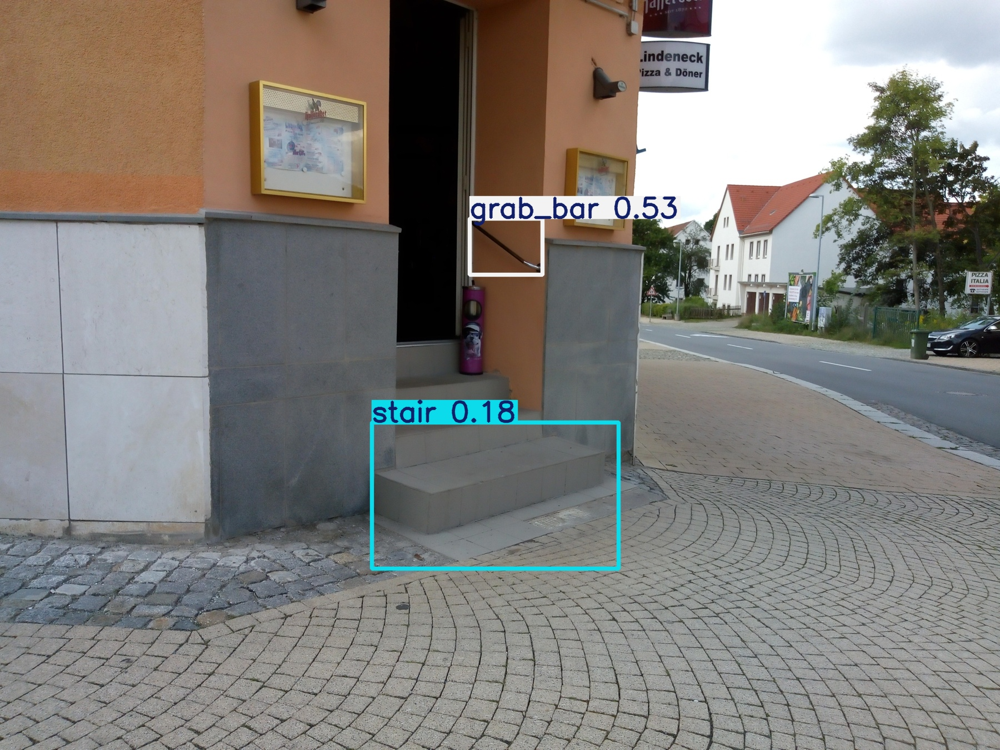

000094376.jpg


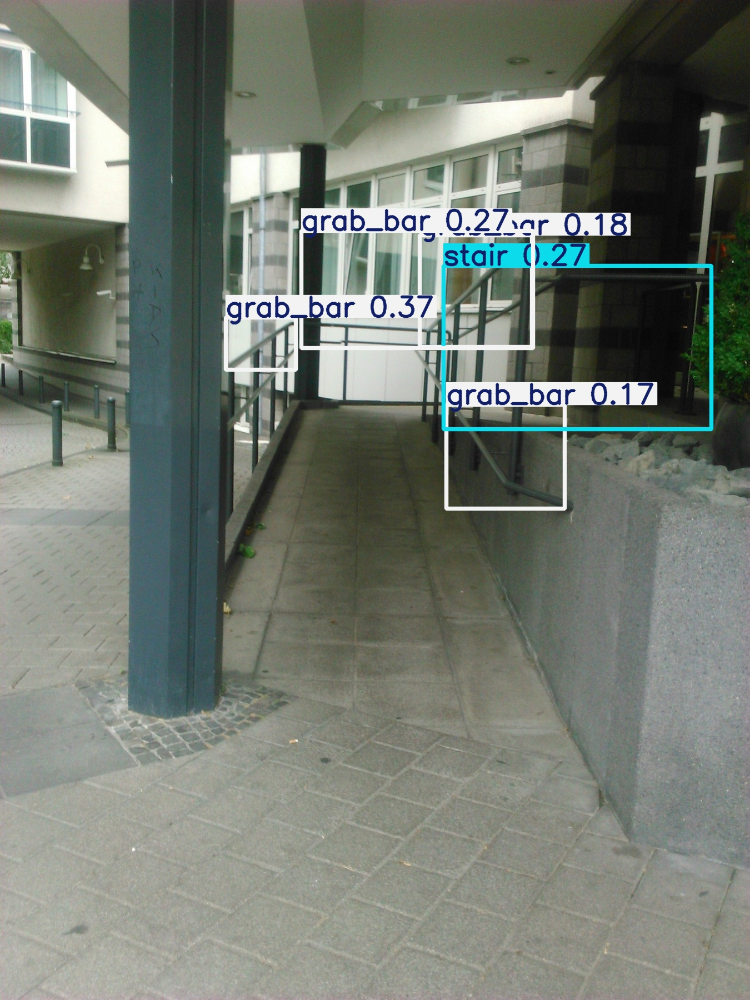

000093270.jpg


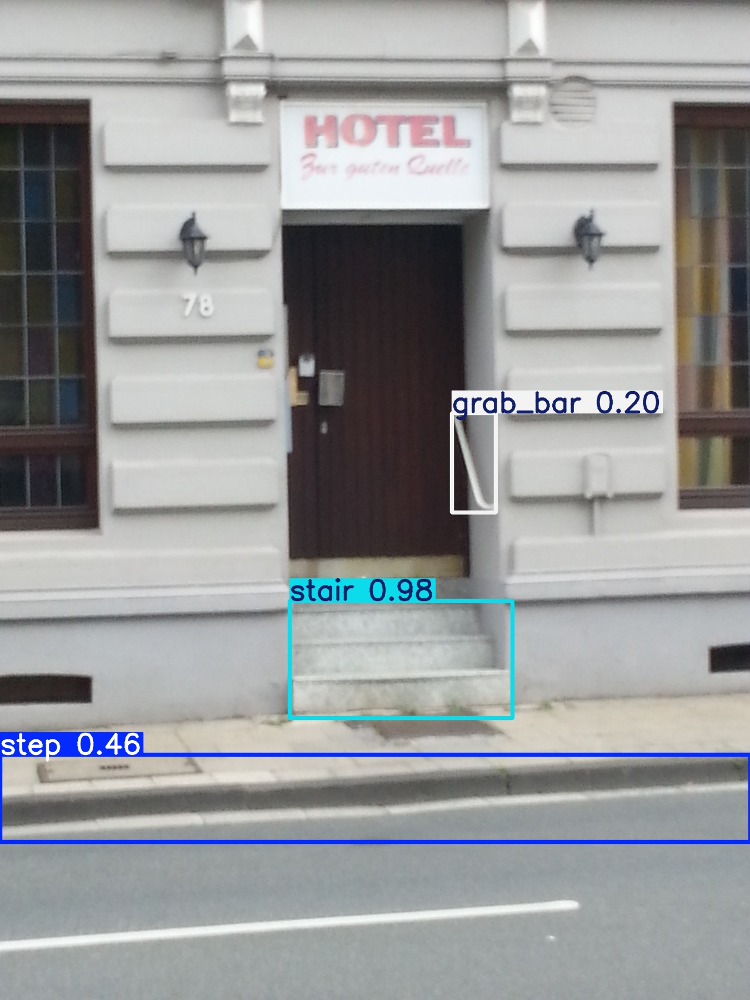

In [41]:
test_preview_files = random.Random(SEED + 1).sample(
    test_prediction_files, k=min(6, len(test_prediction_files))
)
for prediction_file in test_preview_files:
    print(prediction_file.name)
    display(IPyImage(filename=str(prediction_file), width=520))

## 42. Save experiment metrics and reproducibility metadata

This creates machine-readable records of the validation comparison, selected model, test metrics, class-level results, split manifest, and key training settings.

In [42]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
validation_table.to_csv(ARTIFACT_DIR / "validation_comparison.csv", index=False)
per_class_metrics.to_csv(ARTIFACT_DIR / "per_class_test_metrics.csv", index=False)

metadata = {
    "author": "Zainab Amir",
    "dataset_record": RECORD_URL,
    "seed": SEED,
    "classes": CLASS_NAMES,
    "split_sizes": SPLIT_SIZES,
    "training_settings": TRAINING_SETTINGS,
    "experiments": EXPERIMENTS,
    "selected_experiment": SELECTED_EXPERIMENT,
    "selected_checkpoint": str(SELECTED_CHECKPOINT),
    "test_metrics": FINAL_TEST_METRICS,
}
(ARTIFACT_DIR / "project_results.json").write_text(json.dumps(metadata, indent=2))
print("Saved project artifacts to:", ARTIFACT_DIR)

Saved project artifacts to: /content/accessible_austin_final/final_artifacts


## 43. Final project outcome and measured results

**Was the proposed solution implemented?** Yes. The project implemented a YOLOv8n object detector for all four proposed feature classes: steps, stairs, grab bars, and ramps. The completed workflow includes source-data retrieval, XML annotation parsing, YOLO label conversion, pilot dataset preparation, model training, validation-based comparison, held-out testing, and prediction visualizations.

**Does the solution adequately address the real-world problem?** The prototype partially addresses the problem by identifying visible accessibility-related features that may warrant human inspection. It does not provide city-wide accessibility assessment or establish whether a complete pedestrian route is accessible. The pilot is small and is not Austin-specific, and the model's recall indicates that many annotated objects are missed. The system cannot determine route-level accessibility or ADA compliance.

**What metrics were measured, and what values were achieved?** The selected default-mosaic configuration was evaluated on 20 held-out test images containing 85 annotated instances.

| Test metric | Result |
|---|---:|
| Precision | 0.720 |
| Recall | 0.270 |
| mAP@50 | 0.370 |
| mAP@50–95 | 0.209 |

The validation comparison used mAP@50–95 to select the final configuration. The default-mosaic model achieved validation mAP@50–95 of **0.229**, compared with **0.219** for the no-mosaic model, and was therefore selected for the final test evaluation. The no-mosaic configuration achieved higher validation recall (0.409 versus 0.317) and mAP@50 (0.403 versus 0.376), showing a trade-off between the configurations.

The test results indicate that the detector can identify some accessibility-related features, but its low recall and the limited evaluation sample make it unsuitable for unsupervised or high-stakes decisions. The intended application is prioritization for human review.


## 44. Project limitations and interpretation

The project has several limitations:

- **Small pilot dataset:** The pilot contains 200 images, with 20 images in each of the validation and test splits. Metrics from these small samples have substantial uncertainty.
- **Uneven class distribution:** The source dataset has uneven class frequencies. Ramps have substantially fewer original annotations than steps and stairs.
- **Limited geographic representation:** The source images are not a representative sample of Austin sidewalks. Austin-specific generalization has not been demonstrated.
- **Detection errors:** The model may miss features, produce false positives, or place bounding boxes inaccurately. A model score does not establish that a pedestrian route is usable.
- **Narrow experiment scope:** The controlled experiment compares mosaic augmentation enabled with mosaic augmentation disabled. It is not a broad comparison across architectures, confidence thresholds, or all augmentation techniques.
- **Human-review requirement:** The system is a screening aid for human review, not an accessibility audit, legal determination, or substitute for direct inspection by qualified people.

### Conclusion

The project produced a functioning proof-of-concept object detector and a reproducible workflow for identifying visible accessibility-related features in public-space imagery. The current accuracy and evaluation scope are not sufficient for unattended real-world decisions. Larger and more representative datasets, locally annotated Austin imagery, and broader testing would be necessary before practical deployment.
